# ECON 499 | How Do Atlanta Neighborhoods Connect to Shopping Malls?
### A reproducible research walkthrough · 2024

**Study destinations:** Lenox Square, Phipps Plaza, and Ponce City Market.

This notebook documents our research like a student lab report: what we wanted to learn, where the data came from, why we chose each method, what the results show, and where we need to be careful.

**Important:** The public notebook runs without licensed Advan records. It uses publicly shareable ACS and manually recorded driving-distance data plus *previously estimated* model-output CSVs. It does **not** silently recompute the Gravity or Huff models without the licensed source data. See `run_all.py` and `docs/PRIVATE_SETUP.md` for full model reproduction with authorized data.

**Geography warning:** The Advan origin CBG vintage and the crosswalk geography have not been fully reconciled. All flow-based results remain **provisional**, and the 2010 equal-block proxy is a diagnostic rather than a corrected model.

## 1. Set up the project
The notebook finds the repository folder automatically, whether opened from the project root or the `notebooks/` directory. We use standard Python packages and keep all figures in `figures/notebook/` for GitHub preview.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid", context="notebook")
BASE = Path.cwd()
if not (BASE / "data" / "public").exists():
    BASE = BASE.parent
assert (BASE / "data" / "public").exists(), "Open this notebook from the repository or notebooks folder."
FIG = BASE / "figures" / "notebook"
FIG.mkdir(parents=True, exist_ok=True)
def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()
    plt.close()
routes = pd.read_csv(BASE/"data/public/acs_distance_2024.csv", dtype={"ZCTA":str})
maps = pd.read_csv(BASE/"data/public/google_maps_72_routes.csv", dtype={"ZCTA":str})
models = pd.read_csv(BASE/"results/model_comparison.csv")
coverage = pd.read_csv(BASE/"results/origin_coverage_comparison.csv")
holdout = pd.concat([pd.read_csv(p) for p in (BASE/"results").glob("huff_validation_*.csv")],ignore_index=True)
cf = pd.concat([pd.read_csv(p) for p in (BASE/"results").glob("huff_counterfactual_*.csv")],ignore_index=True)
print("Public distance rows:",len(routes),"ZCTAs:",routes.ZCTA.nunique())
display(routes.head(3))

Public distance rows: 72 ZCTAs: 24


,ZCTA,Destination,driving_miles,income,gini,education_share,home_value,poverty_rate
0,30303,Lenox Square,8.4,NaN,0.5695,27.141031,269300.0,60.5
1,30303,Phipps Plaza,9.0,NaN,0.5695,27.141031,269300.0,60.5
2,30303,Ponce City Market,2.9,NaN,0.5695,27.141031,269300.0,60.5


## 2. Data sources and research design
We combined **ACS 2024 five-year neighborhood characteristics**, **72 manually checked Google Maps driving routes** (24 ZCTAs × 3 malls), and **Advan Neighborhood Patterns Plus origin–destination activity** for the model stage.

The distance and ACS graphs below are **descriptive**: they do not use restricted foot-traffic records. The model graphs farther down visualize saved regression and Huff results and are labeled provisional.

**Why ZCTAs?** They let us compare neighborhoods at a familiar ZIP-code-like scale. But a ZCTA is not the same as an individual household, and income at the ZCTA level cannot establish what any specific shopper earns.

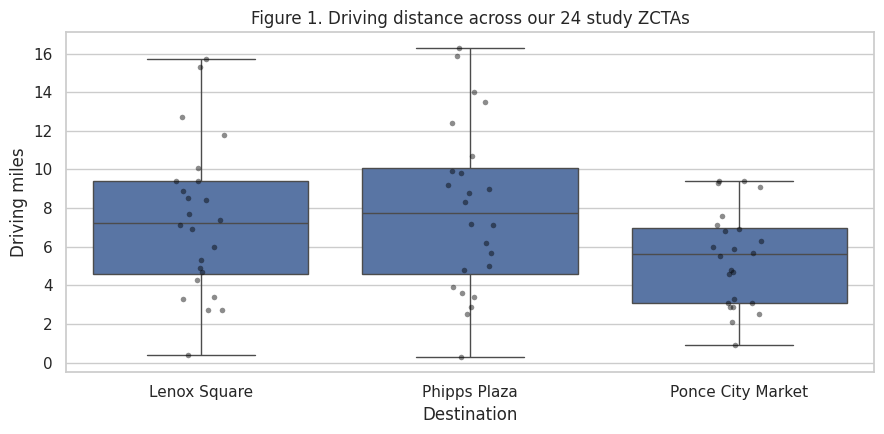

In [2]:
# 1 — Driving-distance distribution by destination
d=routes.dropna(subset=["driving_miles"])
plt.figure(figsize=(9,4.5))
sns.boxplot(data=d,x="Destination",y="driving_miles")
sns.stripplot(data=d,x="Destination",y="driving_miles",color="black",alpha=.45,size=4)
plt.title("Figure 1. Driving distance across our 24 study ZCTAs");plt.ylabel("Driving miles")
save("01_distance_distribution")

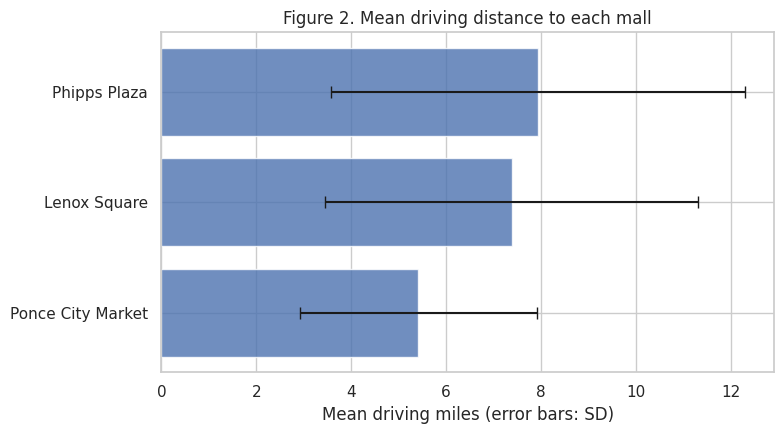

In [3]:
# 2 — Average distance with uncertainty showing variation across origins
g=d.groupby("Destination").driving_miles.agg(["mean","std","count"]).sort_values("mean")
plt.figure(figsize=(8,4.5))
plt.barh(g.index,g["mean"],xerr=g["std"],capsize=4,alpha=.8)
plt.xlabel("Mean driving miles (error bars: SD)");plt.title("Figure 2. Mean driving distance to each mall")
save("02_average_distance")

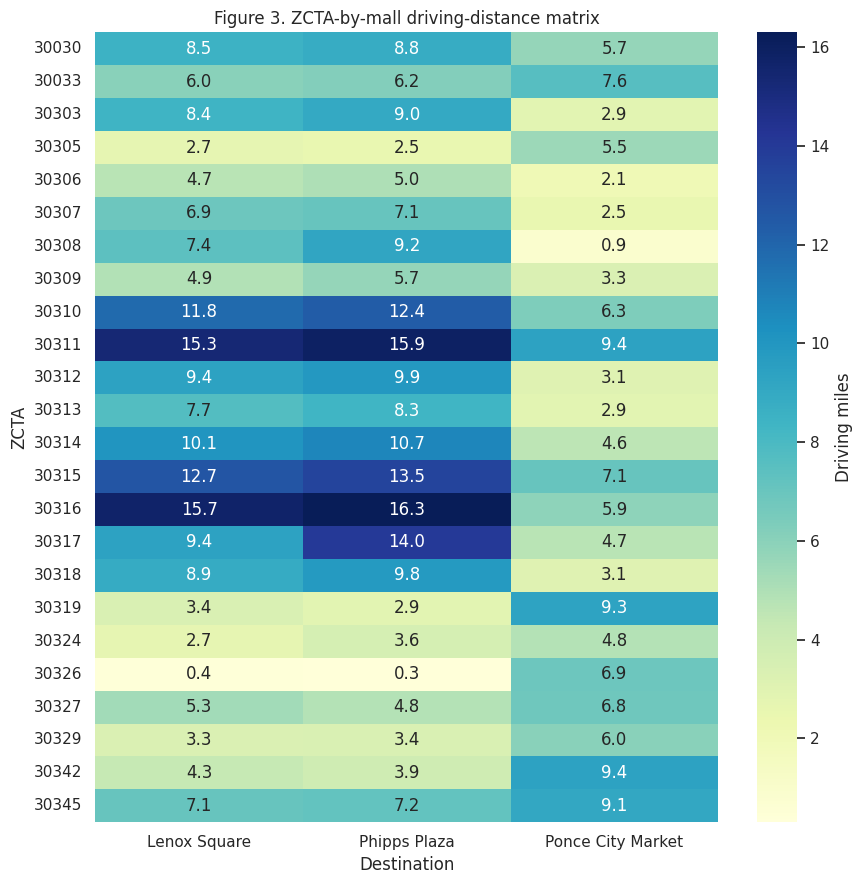

In [4]:
# 3 — Heatmap of routes
pivot=d.pivot(index="ZCTA",columns="Destination",values="driving_miles")
plt.figure(figsize=(9,9))
sns.heatmap(pivot,cmap="YlGnBu",annot=True,fmt=".1f",cbar_kws={"label":"Driving miles"})
plt.title("Figure 3. ZCTA-by-mall driving-distance matrix")
save("03_distance_heatmap")

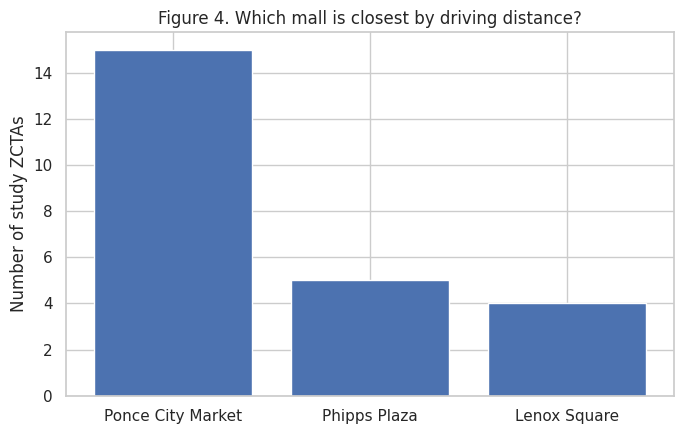

In [5]:
# 4 — Nearest destination
nearest=pivot.idxmin(axis=1).value_counts()
plt.figure(figsize=(7,4.5))
plt.bar(nearest.index,nearest.values)
plt.ylabel("Number of study ZCTAs");plt.title("Figure 4. Which mall is closest by driving distance?")
save("04_nearest_mall")

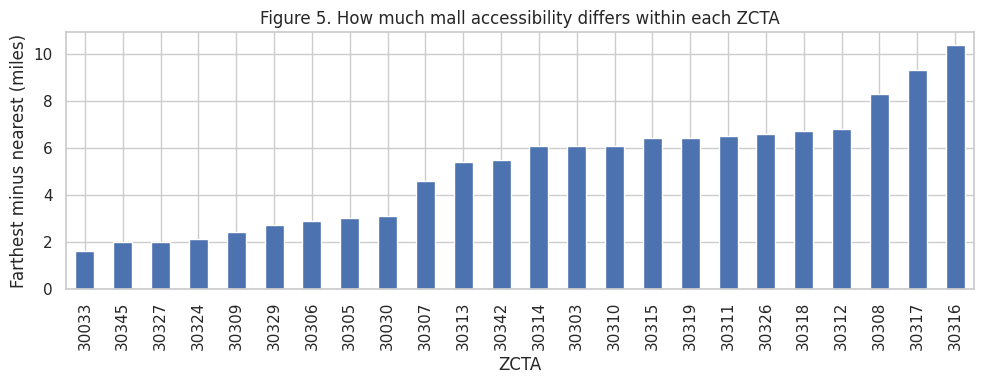

In [6]:
# 5 — Differences in access: closest vs farthest mall
spread=pivot.max(axis=1)-pivot.min(axis=1)
plt.figure(figsize=(10,4))
spread.sort_values().plot(kind="bar")
plt.ylabel("Farthest minus nearest (miles)");plt.title("Figure 5. How much mall accessibility differs within each ZCTA")
save("05_distance_spread")

### Income and inequality
We examine whether neighborhood characteristics line up with accessibility. This is useful background for the Gravity Model, but **correlation here is not evidence of individual shopping behavior**. Missing ACS estimates are left missing rather than filled with invented values.

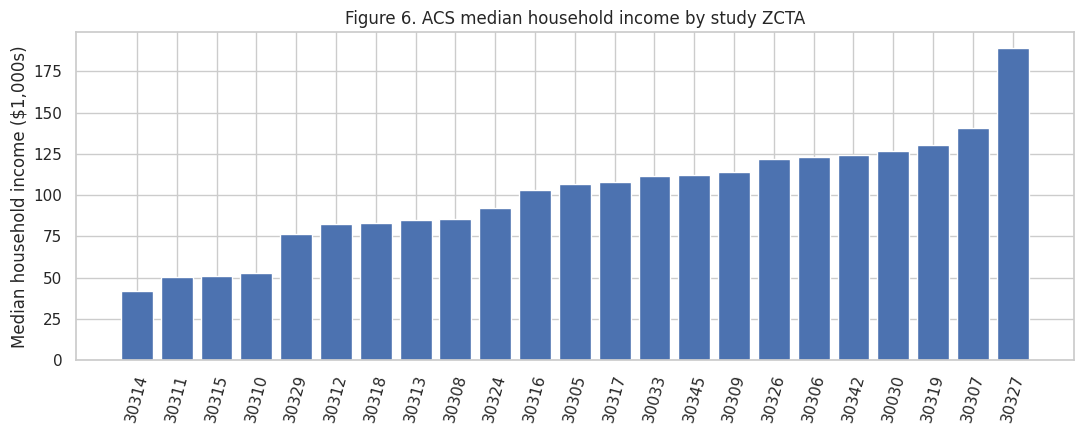

In [7]:
# 6 — Income across ZCTAs, one row per origin
orig=routes.drop_duplicates("ZCTA").copy()
orig["income"]=pd.to_numeric(orig["income"],errors="coerce")
orig["gini"]=pd.to_numeric(orig["gini"],errors="coerce")
plt.figure(figsize=(11,4.5))
a=orig.dropna(subset=["income"]).sort_values("income")
plt.bar(a.ZCTA,a.income/1000)
plt.xticks(rotation=75);plt.ylabel("Median household income ($1,000s)")
plt.title("Figure 6. ACS median household income by study ZCTA")
save("06_income_by_zcta")

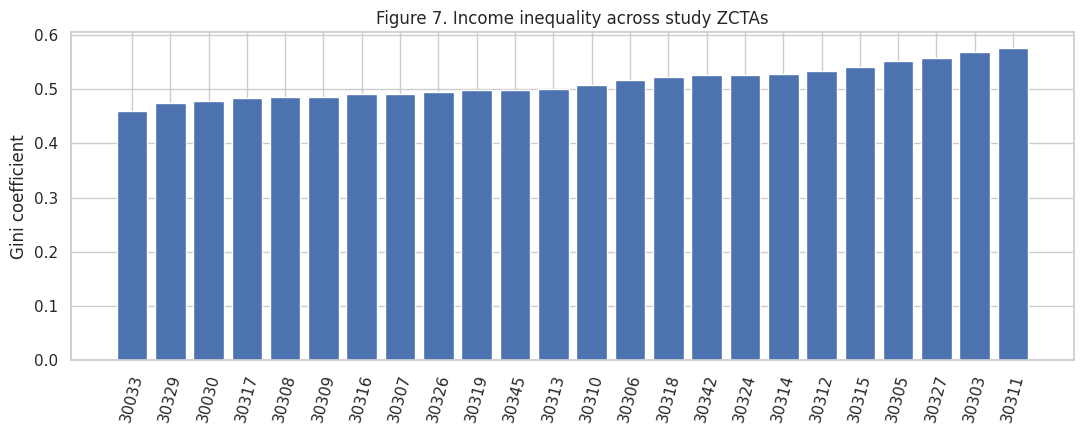

In [8]:
# 7 — Gini inequality
plt.figure(figsize=(11,4.5))
a=orig.dropna(subset=["gini"]).sort_values("gini")
plt.bar(a.ZCTA,a.gini)
plt.xticks(rotation=75);plt.ylabel("Gini coefficient")
plt.title("Figure 7. Income inequality across study ZCTAs")
save("07_gini_by_zcta")

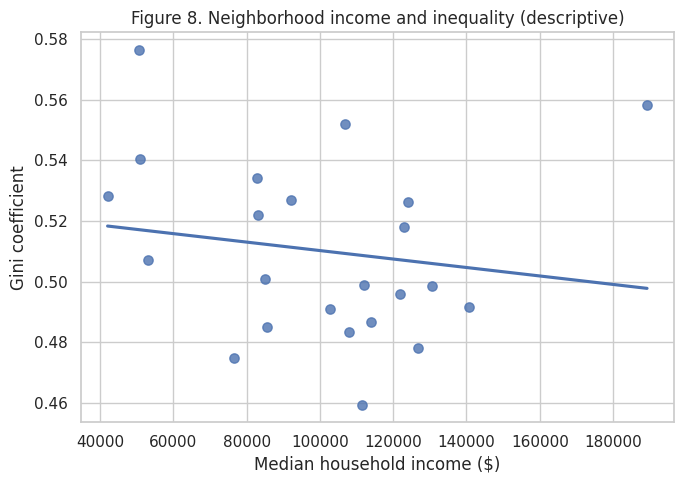

In [9]:
# 8 — Income vs inequality
a=orig.dropna(subset=["income","gini"])
plt.figure(figsize=(7,5))
sns.regplot(data=a,x="income",y="gini",ci=None,scatter_kws={"s":45})
plt.xlabel("Median household income ($)");plt.ylabel("Gini coefficient")
plt.title("Figure 8. Neighborhood income and inequality (descriptive)")
save("08_income_vs_gini")

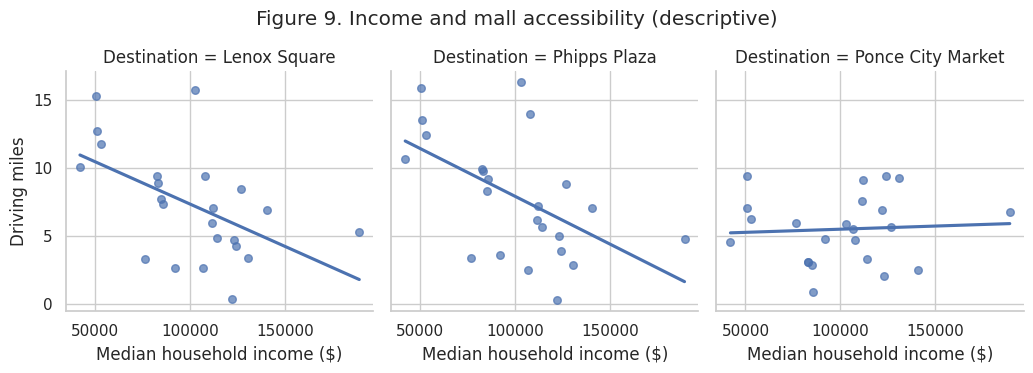

In [10]:
# 9 — Income vs driving distance, each mall separately
a=routes.dropna(subset=["income","driving_miles"])
g=sns.lmplot(data=a,x="income",y="driving_miles",col="Destination",col_wrap=3,
            height=3.5,aspect=1,ci=None,scatter_kws={"alpha":.7,"s":30})
g.set_axis_labels("Median household income ($)","Driving miles")
g.fig.suptitle("Figure 9. Income and mall accessibility (descriptive)",y=1.06)
g.savefig(FIG/"09_income_distance_facets.png",dpi=170,bbox_inches="tight")
plt.show();plt.close("all")

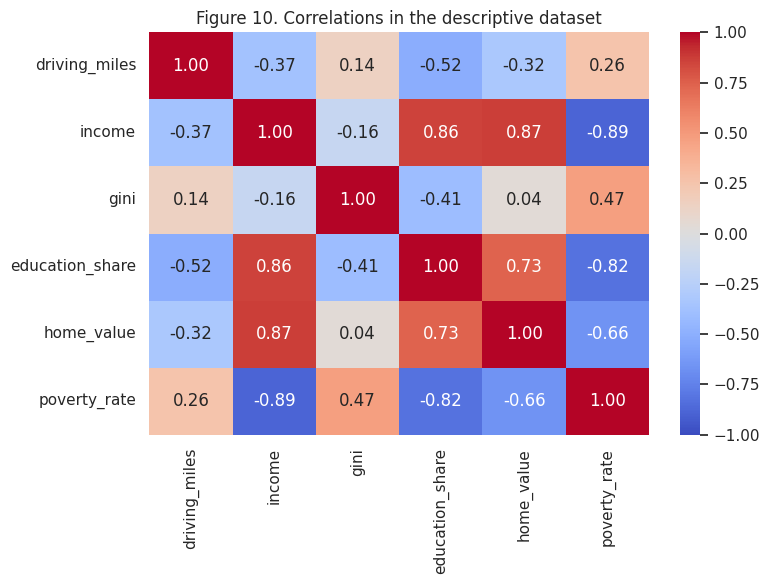

In [11]:
# 10 — Pairwise correlation matrix for observed neighborhood data
numeric=["driving_miles","income","gini","education_share","home_value","poverty_rate"]
corr=routes.drop_duplicates(["ZCTA","Destination"])[numeric].apply(pd.to_numeric,errors="coerce").corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,cmap="coolwarm",center=0,fmt=".2f",vmin=-1,vmax=1)
plt.title("Figure 10. Correlations in the descriptive dataset")
save("10_descriptive_correlations")

## 3. Gravity Model: Does distance predict observed activity?
Our empirical strategy uses a **Poisson pseudo-maximum likelihood (PPML)** model. The outcome is an aggregated activity flow from origin neighborhoods to destination areas. The model relates it to log driving distance and neighborhood characteristics, with fixed effects in relevant specifications.

We do **not** call this a causal effect: unobserved neighborhood preferences, transportation options, mall characteristics, and geography could affect the relationship.

The figures below read the **saved coefficient tables**, not raw licensed Advan flows. The `legacy` specification uses the original crosswalk. The `nhgis_2010_equal_block_proxy` version is a diagnostic and is **not a validated replacement**.

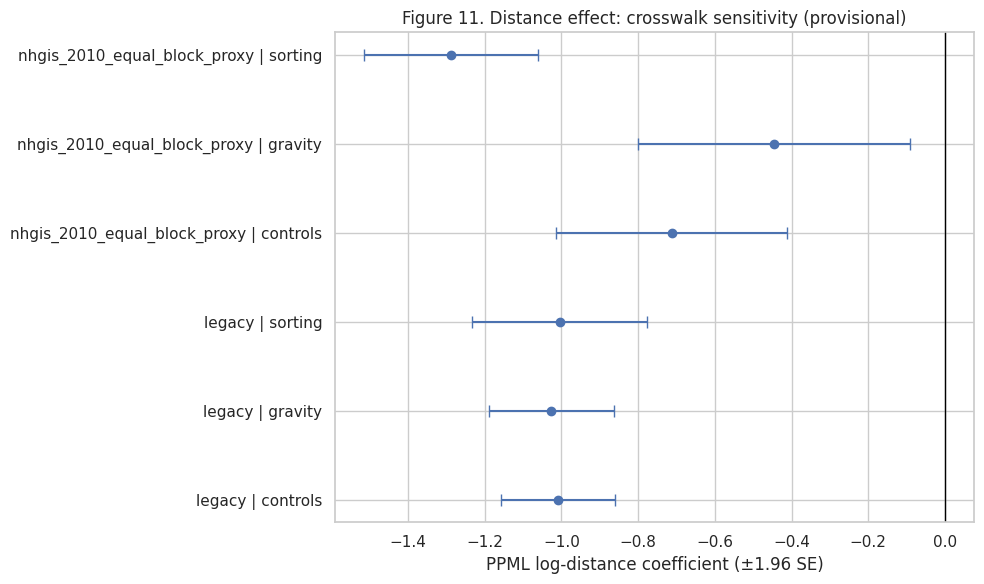

In [12]:
# 11 — Key distance coefficients with 95% normal-approximation intervals
m=models[(models.term=="log_distance") & models.model.isin(["gravity","sorting","controls"])].copy()
m["lo"]=m.coef-1.96*m.se;m["hi"]=m.coef+1.96*m.se
fig,ax=plt.subplots(figsize=(10,5))
for i,(scenario,part) in enumerate(m.groupby("scenario")):
    x=np.arange(len(part))+(i-.5)*.18
    ax.errorbar(part.coef,x,xerr=[part.coef-part.lo,part.hi-part.coef],fmt="o",capsize=4,label=scenario)
    for j,model in enumerate(part.model): pass
ax.axvline(0,color="black",linewidth=1)
# Replot with categorical rows for unambiguous labels
plt.close(fig)
m["spec"]=m["scenario"]+" | "+m["model"]
m=m.sort_values("spec")
plt.figure(figsize=(10,6))
plt.errorbar(m.coef,np.arange(len(m)),xerr=1.96*m.se,fmt="o",capsize=4)
plt.yticks(np.arange(len(m)),m.spec)
plt.axvline(0,color="black",linewidth=1)
plt.xlabel("PPML log-distance coefficient (±1.96 SE)")
plt.title("Figure 11. Distance effect: crosswalk sensitivity (provisional)")
save("11_distance_coefficients")

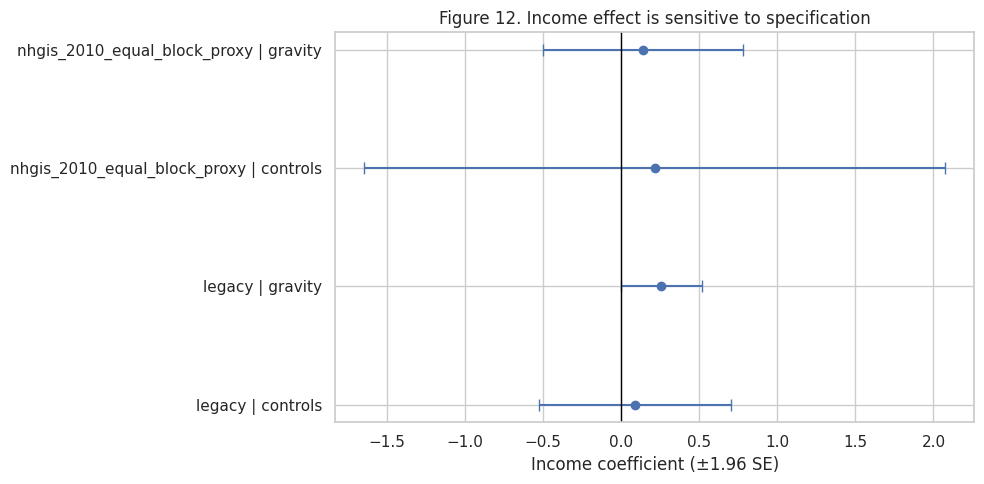

In [13]:
# 12 — Income coefficients across specifications, when estimated
m=models[(models.term=="log_income") & models.model.isin(["gravity","sorting","controls"])].copy()
m=m.sort_values(["scenario","model"])
plt.figure(figsize=(10,5))
plt.errorbar(m.coef,np.arange(len(m)),xerr=1.96*m.se,fmt="o",capsize=4)
plt.yticks(np.arange(len(m)),m.scenario+" | "+m.model)
plt.axvline(0,color="black",linewidth=1)
plt.xlabel("Income coefficient (±1.96 SE)")
plt.title("Figure 12. Income effect is sensitive to specification")
save("12_income_coefficients")

## 4. Geographic crosswalk audit
This is the most important caveat in our study. Our Advan source references **2010 CBG vintage**, while the earlier spatial matching used newer boundaries. The two workflows cover very different portions of the original flows.

The 2010 NHGIS equal-block approach is only a **sensitivity diagnostic**: treating all blocks as equal is not a defensible population-weighted crosswalk. We therefore present both results transparently rather than claiming the issue is fixed.

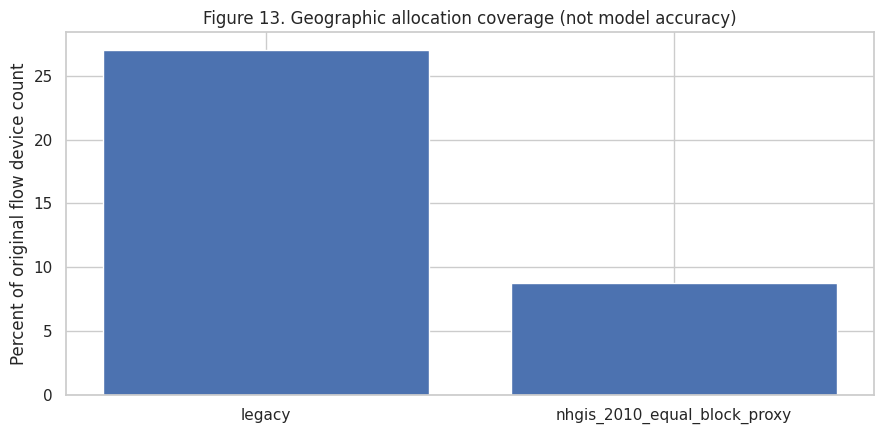

In [14]:
# 13 — How much source activity each geography workflow assigns
plt.figure(figsize=(9,4.5))
plt.bar(coverage.scenario,100*coverage.allocation_fraction_all_origins)
plt.ylabel("Percent of original flow device count")
plt.title("Figure 13. Geographic allocation coverage (not model accuracy)")
save("13_crosswalk_coverage")

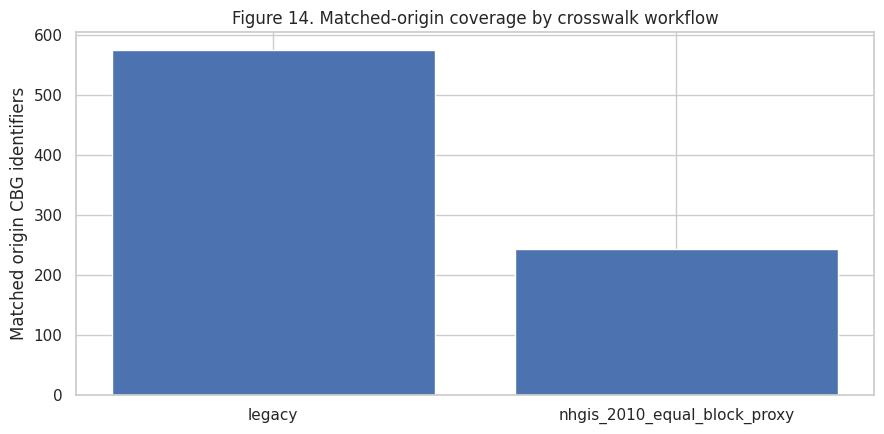

In [15]:
# 14 — Matched CBG counts
plt.figure(figsize=(9,4.5))
plt.bar(coverage.scenario,coverage.origin_ids_matched)
plt.ylabel("Matched origin CBG identifiers")
plt.title("Figure 14. Matched-origin coverage by crosswalk workflow")
save("14_matched_origins")

## 5. Huff Model: How might visitors divide across malls?
The Huff model converts distance-based attractiveness into **relative destination shares**. We estimate it using the existing study flows, then compare its predictions with a simple historical-share benchmark.

A model that sounds more sophisticated is not automatically better: the historical baseline can be harder to beat than expected.

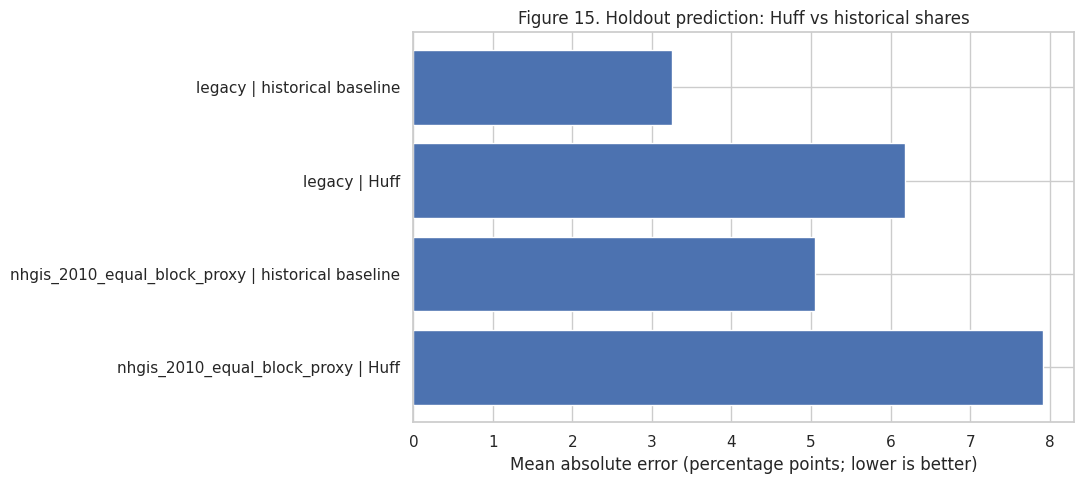

In [16]:
# 15 — Huff holdout errors
hv=holdout[holdout.model=="distance"].copy()
lab=[]; vals=[]
for _,r in hv.iterrows():
    lab += [r.scenario+" | Huff",r.scenario+" | historical baseline"]
    vals += [r.holdout_MAE_pp,r.historical_baseline_MAE_pp]
plt.figure(figsize=(11,5))
plt.barh(lab,vals)
plt.xlabel("Mean absolute error (percentage points; lower is better)")
plt.title("Figure 15. Holdout prediction: Huff vs historical shares")
save("15_huff_holdout")

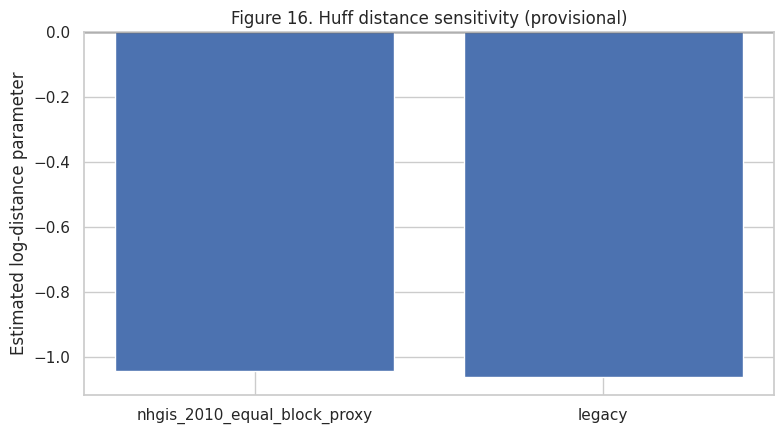

In [17]:
# 16 — Distance parameters in Huff model
plt.figure(figsize=(8,4.5))
plt.bar(hv.scenario,hv.distance_coef)
plt.axhline(0,color="black",linewidth=1)
plt.ylabel("Estimated log-distance parameter")
plt.title("Figure 16. Huff distance sensitivity (provisional)")
save("16_huff_distance")

## 6. Counterfactual: What if travel distance were 20% shorter?
We simulate reducing travel distance to **one** mall at a time. The table reports changes in predicted relative market share in **percentage points**. This is a *model scenario*, not evidence that a road project or transit investment would cause exactly these changes.

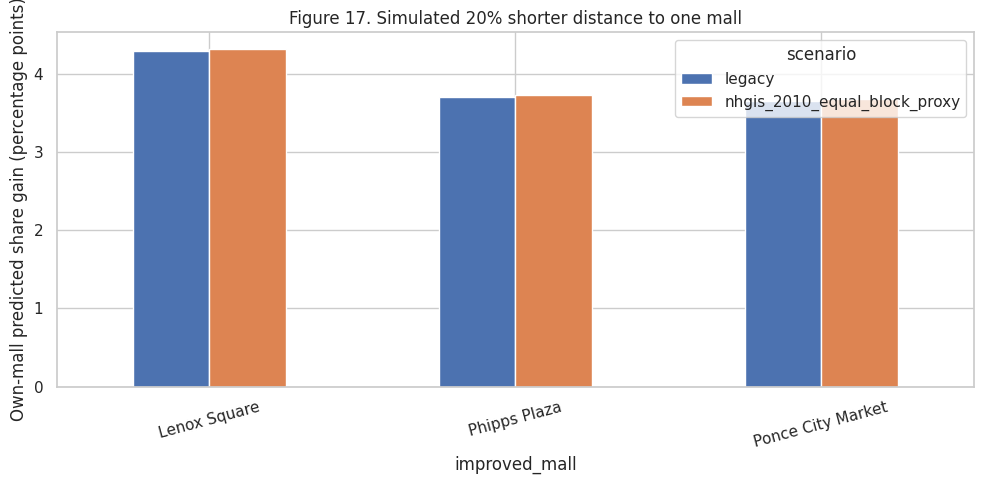

In [18]:
# 17 — Counterfactual: own-mall gain
mall_cols=["Lenox Square","Phipps Plaza","Ponce City Market"]
cf["own_gain_pp"]=cf.apply(lambda r:r[r.improved_mall],axis=1)
pt=cf.pivot(index="improved_mall",columns="scenario",values="own_gain_pp").reindex(mall_cols)
pt.plot(kind="bar",figsize=(10,5))
plt.ylabel("Own-mall predicted share gain (percentage points)")
plt.title("Figure 17. Simulated 20% shorter distance to one mall")
plt.xticks(rotation=15)
save("17_counterfactual_own_gain")

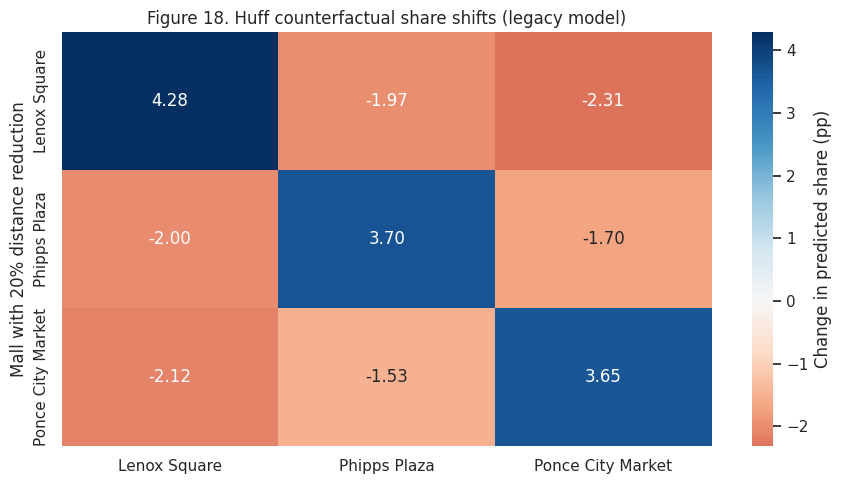

In [19]:
# 18 — Full reallocation of shares under the legacy model
part=cf[cf.scenario=="legacy"].set_index("improved_mall").reindex(mall_cols)
plt.figure(figsize=(9,5))
sns.heatmap(part[mall_cols],annot=True,fmt=".2f",cmap="RdBu",center=0,
            cbar_kws={"label":"Change in predicted share (pp)"})
plt.ylabel("Mall with 20% distance reduction")
plt.title("Figure 18. Huff counterfactual share shifts (legacy model)")
save("18_counterfactual_matrix")

## 7. What we learned, and what we cannot claim
**Main pattern:** Across the saved specifications, driving distance has a negative association with the observed origin-to-destination activity measure. However, the estimated size changes when we change the geographic matching workflow.

**Income:** Some specifications suggest a positive relationship, but it is not stable once additional controls are included. We should not write that higher-income residents definitively prefer one mall.

**Prediction:** The historical-share benchmark performs better than our Huff distance model on the reported holdout tests. This matters because our project is partly about explaining and predicting where activity goes.

**Limitations:** These are aggregated mobility estimates, not observed purchases or a survey of shoppers. The destination areas are geographic proxies, not necessarily exact mall entrances. The unresolved CBG-vintage issue is material. The 20% distance scenario is hypothetical, not a policy causal estimate.

**Reproducibility:** This notebook can regenerate the descriptive and saved-results figures using the public repository. To re-estimate models from origin flows, use the authorized private data and the staged scripts; do not upload licensed Advan records to a public GitHub repository.

**Next research improvement:** Resolve the 2010 CBG-to-ZCTA population-weighted crosswalk, rebuild the OD panel, and rerun the models before treating coefficients as final estimates.